In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
df = pd.read_csv("Mall_Customers.csv")

In [9]:
df.head(10)

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [4]:
df.shape

(200, 5)

In [5]:
 df.isna().sum().sum()

np.int64(0)

In [6]:
 df.duplicated().sum()

np.int64(0)

In [8]:
 df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [12]:
features_to_scale = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df[features_to_scale])


In [13]:
df_scaled = pd.DataFrame(scaled_features, columns=features_to_scale)
print("Means after scaling:", np.round(df_scaled.mean().values, 2))
print("Std after scaling:", np.round(df_scaled.std().values, 2))
print("\nScaled Dataset Preview:\n", df_scaled.head())

Means after scaling: [-0. -0. -0.]
Std after scaling: [1. 1. 1.]

Scaled Dataset Preview:
         Age  Annual Income (k$)  Spending Score (1-100)
0 -1.424569           -1.738999               -0.434801
1 -1.281035           -1.738999                1.195704
2 -1.352802           -1.700830               -1.715913
3 -1.137502           -1.700830                1.040418
4 -0.563369           -1.662660               -0.395980


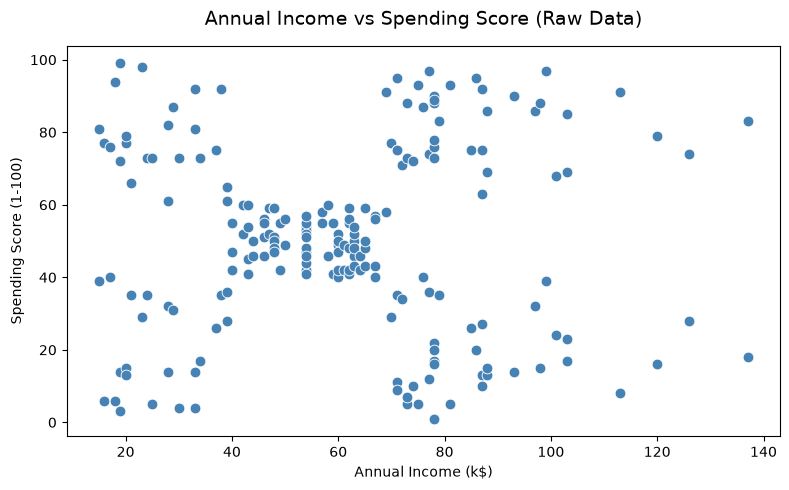

In [18]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)", s=60, color="steelblue")
plt.title("Annual Income vs Spending Score (Raw Data)", fontsize=14, pad=15)
plt.tight_layout()
plt.show()


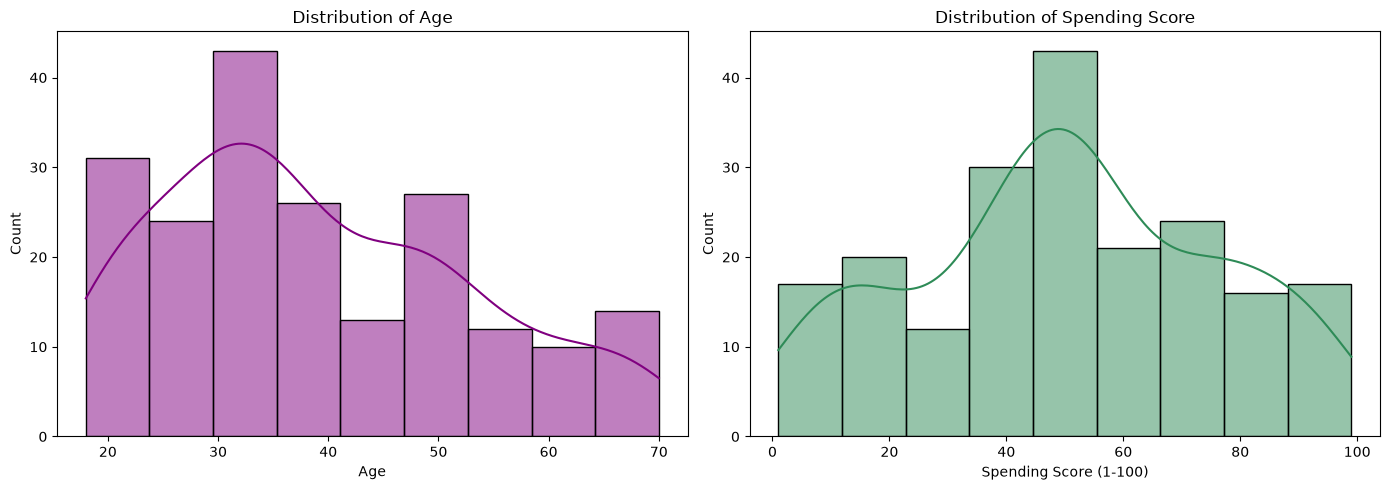

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=df, x="Age", ax=axes[0], kde=True, color="purple")
axes[0].set_title("Distribution of Age")

sns.histplot(data=df, x="Spending Score (1-100)", ax=axes[1], kde=True, color="seagreen")
axes[1].set_title("Distribution of Spending Score")

plt.tight_layout()
plt.show()

In [21]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
X_scaled = df_scaled[["Annual Income (k$)", "Spending Score (1-100)"]].values
inertia = []
silhouette_scores = []
k_range = range(2, 11)
for k in k_range:
    kmeans = KMeans(n_clusters=k, init="k-means++", random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, kmeans.labels_))
    print(f"k={k}: silhouette={silhouette_score(X_scaled, kmeans.labels_):.3f}")

k=2: silhouette=0.321
k=3: silhouette=0.467
k=4: silhouette=0.494
k=5: silhouette=0.555
k=6: silhouette=0.540
k=7: silhouette=0.528
k=8: silhouette=0.455
k=9: silhouette=0.457
k=10: silhouette=0.443


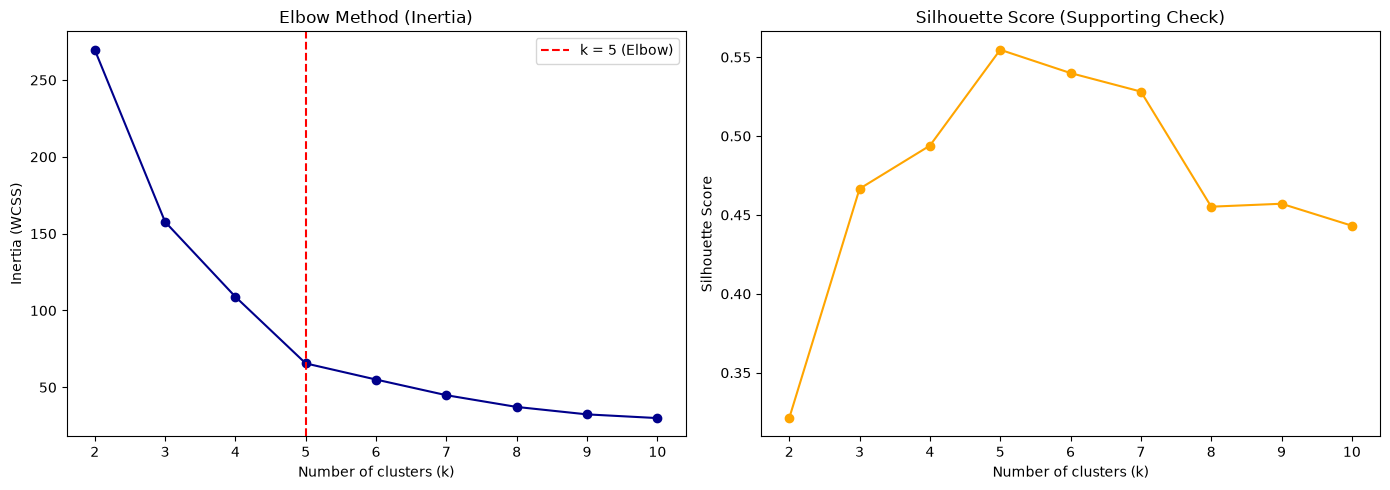

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Elbow Curve
axes[0].plot(k_range, inertia, marker='o', color='darkblue')
axes[0].axvline(x=5, color='red', linestyle='--', label='k = 5 (Elbow)')
axes[0].set_title("Elbow Method (Inertia)", fontsize=12)
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia (WCSS)")
axes[0].legend()
# Silhouette Curve
axes[1].plot(k_range, silhouette_scores, marker='o', color='orange')
axes[1].set_title("Silhouette Score (Supporting Check)", fontsize=12)
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()


In [26]:
final_kmeans = KMeans(n_clusters=5, init="k-means++", random_state=42, n_init=10)
df["Cluster"] = final_kmeans.fit_transform(X_scaled).argmin(axis=1)
print("\nCustomers per cluster:\n", df["Cluster"].value_counts().sort_index())
print(f"\nFinal Silhouette Score: {silhouette_score(X_scaled, final_kmeans.labels_):.3f}")



Customers per cluster:
 Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Final Silhouette Score: 0.555


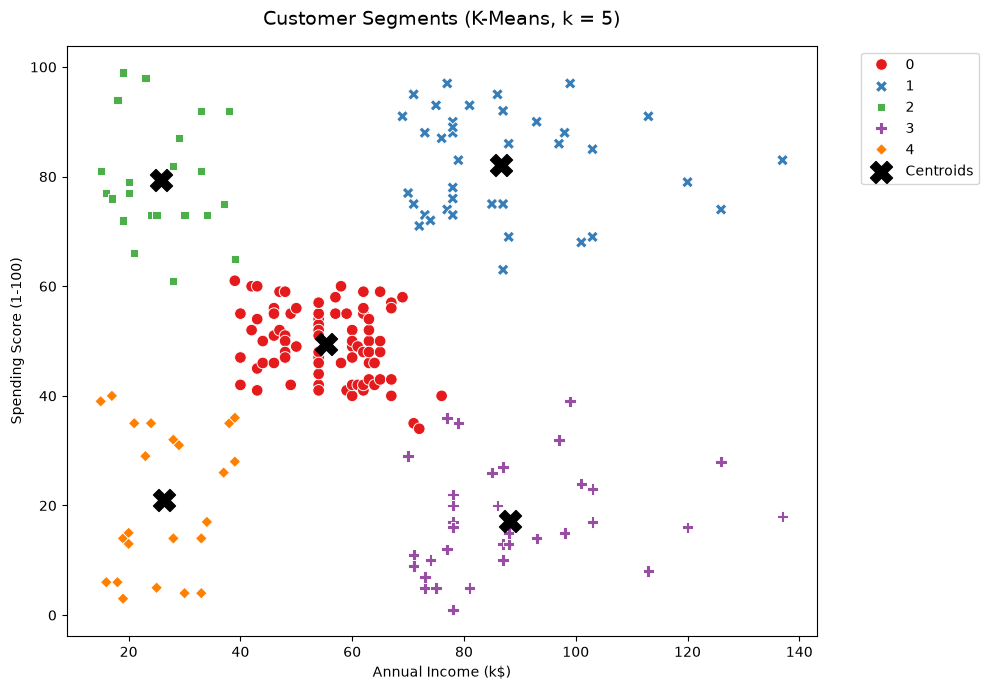

In [33]:
plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=df, 
    x="Annual Income (k$)", 
    y="Spending Score (1-100)", 
    hue="Cluster", 
    palette="Set1", 
    s=70, 
    style="Cluster"
)
plt.scatter(raw_centroids[:, 0], raw_centroids[:, 1], s=250, c='black', marker='X', label='Centroids')
plt.title("Customer Segments (K-Means, k = 5)", fontsize=14, pad=15)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [34]:
scaled_centroids = final_kmeans.cluster_centers_
dummy_centroids = np.zeros((5, 3))
dummy_centroids[:, 1:] = scaled_centroids
raw_centroids = scaler.inverse_transform(dummy_centroids)[:, 1:]


In [39]:
summary_table = df.groupby("Cluster").agg(
    customers=("CustomerID", "count"),
    avg_age=("Age", "mean"),
    avg_income=("Annual Income (k$)", "mean"),
    avg_spending=("Spending Score (1-100)", "mean")
).reset_index()
segment_labels = {
    0: "Average income, average spending (Standard)",
    1: "High income, high spending (Target)",
    2: "Low income, high spending (Impulsive)",
    3: "High income, low spending (Careful)",
    4: "Low income, low spending (Frugal)"
}
summary_table["Segment Label"] = summary_table["Cluster"].map(segment_labels)
print(summary_table.to_string(index=False))

 Cluster  customers   avg_age  avg_income  avg_spending                               Segment Label
       0         81 42.716049   55.296296     49.518519 Average income, average spending (Standard)
       1         39 32.692308   86.538462     82.128205         High income, high spending (Target)
       2         22 25.272727   25.727273     79.363636       Low income, high spending (Impulsive)
       3         35 41.114286   88.200000     17.114286         High income, low spending (Careful)
       4         23 45.217391   26.304348     20.913043           Low income, low spending (Frugal)
